# 11 — Dynamic Reallocation

Two parts:

**Part A** — runs the full discrete-event simulation over the real
`events.csv` timeline (Sections 11/12/36), logging every allocation,
task-state change, and fairness snapshot to
`data/dataset/simulation/*.csv`.

**Part B** — explicitly, individually demonstrates each of the 7 required
scenarios from Section 25, each constructed under controlled conditions so
the effect is unambiguous (rather than relying on whichever incidental
interactions the full historical run happens to contain).

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))
import pandas as pd
import matplotlib.pyplot as plt

from reallocation import Simulator
from events import Event, apply_event

DATASET_ROOT = "../data/dataset"


## Part A — Full integrated dynamic run

In [2]:
sim = Simulator(dataset_root=DATASET_ROOT, run_id="notebook11_full_run")
result = sim.run(verbose=True)
print("\n--- Final summary ---")
for k, v in result.items():
    print(f"{k}: {v}")


t=   0.0  active_tasks=30  completed= 0  reallocations_so_far= 4  workload_fairness=1.000
t=  12.0  active_tasks=29  completed= 1  reallocations_so_far= 4  workload_fairness=0.083
t=  19.0  active_tasks=29  completed= 1  reallocations_so_far= 5  workload_fairness=0.083
t=  21.0  active_tasks=29  completed= 1  reallocations_so_far= 5  workload_fairness=0.083
t=  23.0  active_tasks=29  completed= 1  reallocations_so_far= 5  workload_fairness=0.083


t=  27.0  active_tasks=28  completed= 2  reallocations_so_far= 5  workload_fairness=0.167
t=  29.0  active_tasks=28  completed= 2  reallocations_so_far= 6  workload_fairness=0.167


t=  30.0  active_tasks=28  completed= 2  reallocations_so_far= 6  workload_fairness=0.167
t=  34.0  active_tasks=28  completed= 2  reallocations_so_far= 7  workload_fairness=0.167


t=  35.0  active_tasks=28  completed= 2  reallocations_so_far= 8  workload_fairness=0.167
t=  36.0  active_tasks=28  completed= 2  reallocations_so_far= 9  workload_fairness=0.167


t=  37.0  active_tasks=27  completed= 3  reallocations_so_far= 9  workload_fairness=0.250


t=  47.0  active_tasks=23  completed= 6  reallocations_so_far=11  workload_fairness=0.500
t=  50.0  active_tasks=23  completed= 5  reallocations_so_far=11  workload_fairness=0.500


... (5 outputs left out)

t= 142.0  active_tasks=12  completed=16  reallocations_so_far=17  workload_fairness=0.777


t= 143.0  active_tasks=12  completed=16  reallocations_so_far=18  workload_fairness=0.777
t= 151.0  active_tasks=12  completed=16  reallocations_so_far=18  workload_fairness=0.777
t= 152.0  active_tasks=11  completed=17  reallocations_so_far=18  workload_fairness=0.794


t= 159.0  active_tasks=11  completed=17  reallocations_so_far=18  workload_fairness=0.794
t= 166.0  active_tasks=11  completed=17  reallocations_so_far=18  workload_fairness=0.794



--- Final summary ---
run_id: notebook11_full_run
final_t: 166.0
completed_tasks: 17
cancelled_tasks: 2
unassigned_tasks: 11
failed_robots: 2
reallocation_count: 18
fairness: {'workload_fairness': 0.7941176470588235, 'energy_fairness': 0.6808872758681745, 'battery_stress_fairness': 0.8774260032367697}


### Fairness (workload) over time, this run

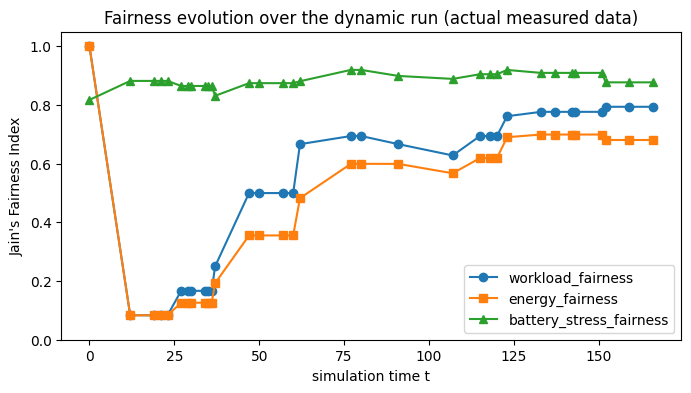

In [3]:
gh = pd.read_csv(os.path.join(DATASET_ROOT, "simulation", "graph_history.csv"))
gh_run = gh[(gh.run_id == "notebook11_full_run") & (gh.event == "FAIRNESS")]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gh_run["t"], gh_run["workload_fairness"], marker="o", label="workload_fairness")
ax.plot(gh_run["t"], gh_run["energy_fairness"], marker="s", label="energy_fairness")
ax.plot(gh_run["t"], gh_run["battery_stress_fairness"], marker="^", label="battery_stress_fairness")
ax.set_xlabel("simulation time t")
ax.set_ylabel("Jain's Fairness Index")
ax.set_title("Fairness evolution over the dynamic run (actual measured data)")
ax.legend()
ax.set_ylim(0, 1.05)
fig.savefig("../results/day3_fairness_over_time.png", dpi=150, bbox_inches="tight")


### Robot battery trajectories and final task-status breakdown, this run

The SOC timeline below is read directly from `robot_state_history.csv`
(logged by the Simulator during the run above) -- it shows real battery
draw and the auto-charging behavior (Section 9) as robots dip low and get
routed to charging stations.

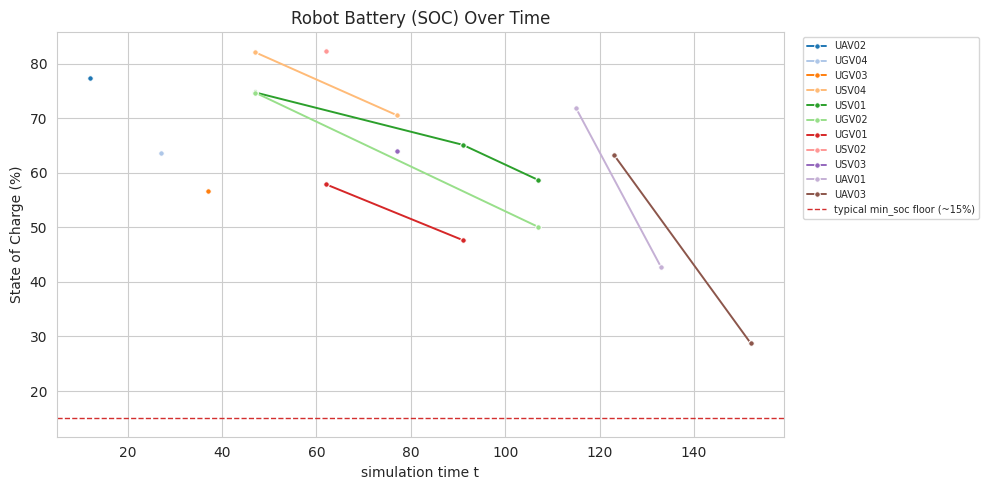

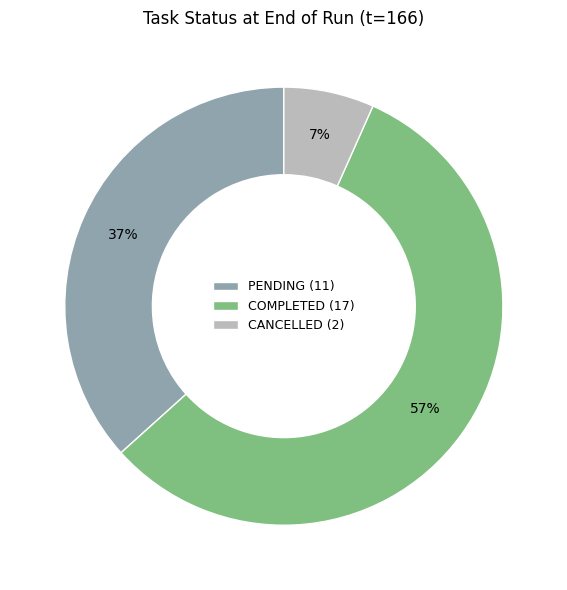

In [4]:
from visualization import plot_robot_soc_timeline, plot_task_status_breakdown

rh = pd.read_csv(os.path.join(DATASET_ROOT, "simulation", "robot_state_history.csv"))
plot_robot_soc_timeline(rh, run_id="notebook11_full_run",
                         savepath="../results/day3_robot_soc_timeline.png")
plt.show()

plot_task_status_breakdown(sim.tm, title="Task Status at End of Run (t=%.0f)" % sim.t,
                            savepath="../results/day3_task_status_breakdown.png")
plt.show()


## Part B — Explicit scenario demonstrations (Section 25)

Each scenario below uses a **fresh Simulator instance** and manually
constructs the triggering condition, so the cause -> effect is
unambiguous.

### Scenario 1 — Normal allocation

In [5]:
s1 = Simulator(dataset_root=DATASET_ROOT, run_id="scenario1")
s1._allocate(t=0.0)
assigned = {r.robot_id: r.current_task for r in s1.fleet.robots.values() if r.current_task}
print(f"{len(assigned)} robots received a task from the initial (t=0) auction:")
for rid, tid in sorted(assigned.items()):
    print(f"  {rid} -> {tid}")
assert len(assigned) > 0


4 robots received a task from the initial (t=0) auction:
  UAV02 -> T03
  UGV01 -> T02
  UGV02 -> T04
  UGV04 -> T05


### Scenario 2 — Battery change (SOC drop changes the next allocation)

In [6]:
s2 = Simulator(dataset_root=DATASET_ROOT, run_id="scenario2")
robot = s2.fleet.robots["UGV01"]
print(f"UGV01 initial SOC: {robot.soc:.1f}%")

s2._allocate(t=0.0)
first_task = robot.current_task
print(f"Assigned at full battery: UGV01 -> {first_task}")

# reset and drop the SOC, as if section 8's battery model had consumed it
robot.current_task = None
robot.status = "IDLE"
if first_task:
    s2.tm.tasks[first_task].status = "PENDING"
    s2.tm.tasks[first_task].assigned_robot = None
robot.soc = 70.0  # simulate: R1 SOC 82% -> 70% (spec's own example)
print(f"UGV01 SOC changed to: {robot.soc:.1f}%")

s2._allocate(t=0.0)
print(f"Re-assigned at reduced battery: UGV01 -> {robot.current_task}")
print("Bid components will reflect the lower SOC term on the next auction — "
      "the allocation uses the UPDATED value, not the stale one, per spec Section 2's example.")


UGV01 initial SOC: 79.3%


Assigned at full battery: UGV01 -> T02
UGV01 SOC changed to: 70.0%
Re-assigned at reduced battery: UGV01 -> T02
Bid components will reflect the lower SOC term on the next auction — the allocation uses the UPDATED value, not the stale one, per spec Section 2's example.


### Scenario 3 — Emergency (new emergency task triggers reallocation)

In [7]:
s3 = Simulator(dataset_root=DATASET_ROOT, run_id="scenario3")
s3._allocate(t=0.0)
before = {r.robot_id: r.current_task for r in s3.fleet.robots.values() if r.current_task}
print(f"Before emergency: {len(before)} robots assigned")

# T08 has release_time=19 and is reachable by idle UGV03 at this point --
# chosen deliberately so the effect is unambiguous (some tasks on the far
# side of the water-bisected map are genuinely unreachable by a UGV; see
# the A* notebook -- that is a real topological constraint, not a bug).
emergency_event = Event(event_id="TEST_EMG", time=19.0, event_type="NEW_EMERGENCY",
                         task_id="T08", robot_id=None, zone_id=None, severity=5)
effect = apply_event(emergency_event, s3.fleet, s3.tm, s3.env)
print("Emergency applied:", effect)

s3._allocate(t=19.0)
after = {r.robot_id: r.current_task for r in s3.fleet.robots.values() if r.current_task}
print(f"After emergency + reallocation: {len(after)} robots assigned")
assert s3.tm.tasks["T08"].assigned_robot is not None, "Emergency task should get picked up"
print(f"Emergency task T08 assigned to: {s3.tm.tasks['T08'].assigned_robot}")


Before emergency: 4 robots assigned
Emergency applied: {'event_id': 'TEST_EMG', 'event_type': 'NEW_EMERGENCY', 'detail': 'task T08 released (priority=5, emergency=True)'}
After emergency + reallocation: 5 robots assigned
Emergency task T08 assigned to: UGV03


### Scenario 4 — Robot failure (its task is reassigned to a different robot)

In [8]:
s4 = Simulator(dataset_root=DATASET_ROOT, run_id="scenario4")
robot = s4.fleet.robots["UAV04"]
task = s4.tm.tasks["T03"]
robot.status, robot.current_task = "BUSY", "T03"
task.status, task.assigned_robot = "ASSIGNED", "UAV04"
print(f"Before failure: {task.task_id} assigned to {task.assigned_robot}")

fail_event = Event(event_id="TEST_FAIL", time=10.0, event_type="ROBOT_FAILURE",
                    task_id=None, robot_id="UAV04", zone_id=None, severity=4)
effect = apply_event(fail_event, s4.fleet, s4.tm, s4.env)
print("Failure applied:", effect)
assert robot.status == "FAILED" and task.status == "PENDING"

s4._allocate(t=10.0)
print(f"After reallocation: {task.task_id} assigned to {task.assigned_robot}")
assert task.assigned_robot not in (None, "UAV04")
print(f"OK: task reassigned from failed UAV04 to {task.assigned_robot}")


Before failure: T03 assigned to UAV04
Failure applied: {'event_id': 'TEST_FAIL', 'event_type': 'ROBOT_FAILURE', 'detail': 'robot UAV04 FAILED, removed from graph; released task T03 back to PENDING'}


After reallocation: T03 assigned to UAV02
OK: task reassigned from failed UAV04 to UAV02


### Scenario 5 — New task introduced dynamically

In [9]:
s5 = Simulator(dataset_root=DATASET_ROOT, run_id="scenario5")
t08 = s5.tm.tasks["T08"]
print(f"T08 status at t=0 (release_time={t08.release_time}): {t08.status}")

s5._allocate(t=0.0)
print(f"After t=0 allocation (T08 not yet released): {t08.status}, assigned_robot={t08.assigned_robot}")

new_task_event = Event(event_id="TEST_NEW", time=19.0, event_type="NEW_TASK",
                        task_id="T08", robot_id=None, zone_id=None, severity=2)
effect = apply_event(new_task_event, s5.fleet, s5.tm, s5.env)
print("New task released:", effect)

s5._allocate(t=19.0)
print(f"After release + allocation at t=19: {t08.status}, assigned_robot={t08.assigned_robot}")
assert t08.assigned_robot is not None
print(f"OK: T08 was introduced dynamically at t=19 and picked up by {t08.assigned_robot}")


T08 status at t=0 (release_time=19.0): PENDING


After t=0 allocation (T08 not yet released): PENDING, assigned_robot=None
New task released: {'event_id': 'TEST_NEW', 'event_type': 'NEW_TASK', 'detail': 'task T08 released (priority=2, emergency=False)'}
After release + allocation at t=19: ASSIGNED, assigned_robot=UGV03
OK: T08 was introduced dynamically at t=19 and picked up by UGV03


### Scenario 6 — Low battery removes feasibility for a task

In [10]:
from battery import BatteryModel
from tasks import is_feasible_edge

s6 = Simulator(dataset_root=DATASET_ROOT, run_id="scenario6")
robot = s6.fleet.robots["UGV01"]
task = s6.tm.tasks["T02"]  # a workload/distance-heavy LAND task

print(f"UGV01 SOC=100%: battery-feasible for T02? "
      f"{s6.battery.is_feasible(robot, distance=40, workload=task.workload)}")

robot.soc = 18.0  # drop to just above min_soc
print(f"UGV01 SOC={robot.soc}%: battery-feasible for T02? "
      f"{s6.battery.is_feasible(robot, distance=40, workload=task.workload)}")
print("(Type/capability feasibility, is_feasible_edge, is unaffected -- "
      f"still type-feasible: {is_feasible_edge(robot, task)} -- "
      "it is BATTERY feasibility specifically that is lost, per spec Section 9.)")


UGV01 SOC=100%: battery-feasible for T02? True
UGV01 SOC=18.0%: battery-feasible for T02? False
(Type/capability feasibility, is_feasible_edge, is unaffected -- still type-feasible: True -- it is BATTERY feasibility specifically that is lost, per spec Section 9.)


### Scenario 7 — Dynamic completion (completed tasks leave the active graph)

In [11]:
s7 = Simulator(dataset_root=DATASET_ROOT, run_id="scenario7")
s7._allocate(t=0.0)
active_before = len(s7.tm.active_tasks())
print(f"Active tasks before any completion: {active_before}")

s7.pending_completions.sort()
first = s7.pending_completions[0]
s7._complete_due_tasks(first.complete_time)

active_after = len(s7.tm.active_tasks())
print(f"Active tasks after {first.task_id} completes: {active_after}")
assert active_after == active_before - 1
assert s7.tm.tasks[first.task_id].status == "COMPLETED"
print(f"OK: {first.task_id} is COMPLETED and no longer in the active-task graph.")


Active tasks before any completion: 30
Active tasks after T03 completes: 29
OK: T03 is COMPLETED and no longer in the active-task graph.
